# Wearable Human Activity Recognition (UCI HAR)
## Part 2: Modern (Transformer) & Advanced Hybrid (1D-CNN + Bi-LSTM + Custom Attention) Architectures

### Objectives
1. **Modern Architecture:** Build and evaluate a **Time-Series Transformer Encoder** using `MultiHeadAttention` and learnable positional embeddings under the exact same subject-wise split and random seeds (`42, 123, 2026`).
2. **Custom Hand-Written Component:** Integrate our custom `TemporalAttentionLayer` implemented from scratch in `src/models/custom_layers.py`.
3. **Advanced Hybrid Architecture:** Combine `1D-CNN` local feature extraction, `Bidirectional LSTM` sequence modeling, and our custom `TemporalAttentionLayer` to improve classification performance across both dynamic and static activities.

In [3]:
import os, sys, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print("Current Working Directory:", os.getcwd())

# Search up to 3 levels up for 'src' or 'loader.py'
current = os.path.abspath(".")
PROJECT_ROOT = None
for _ in range(4):
    if os.path.exists(os.path.join(current, "src", "datasets", "loader.py")):
        PROJECT_ROOT = current
        break
    current = os.path.dirname(current)

if PROJECT_ROOT is None:
    # Fallback: check D:\project-har directly
    PROJECT_ROOT = r"D:\project-har"

print("Detected PROJECT_ROOT:", PROJECT_ROOT)
sys.path.insert(0, os.path.join(PROJECT_ROOT, "src"))

from datasets.loader import get_har_data, ACTIVITY_LABELS
from models.custom_layers import TemporalAttentionLayer

DATA_DIR = os.path.join(PROJECT_ROOT, "data", "UCI HAR Dataset")
SAVED_MODELS_DIR = os.path.join(PROJECT_ROOT, "saved_models")
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
SEEDS = [42, 123, 2026]

_, _, _, (X_train, y_train, X_val, y_val, X_test, y_test), stats = get_har_data(DATA_DIR)
print(f"Loaded identical leakage-free split -> Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Current Working Directory: c:\Users\moham\Downloads\MotionMindset_HAR_Project_\notebooks
Detected PROJECT_ROOT: c:\Users\moham\Downloads\MotionMindset_HAR_Project_
Loaded identical leakage-free split -> Train: (6037, 128, 9), Val: (1315, 128, 9), Test: (2947, 128, 9)


---
### Step 1: Modern Deep Learning Model — Time-Series Transformer Encoder
To capture global self-attention across all 128 time steps simultaneously without recurrence, we implement an encoder-only **Time-Series Transformer** (`d_model=64`, `4 attention heads`, learnable positional embeddings) and evaluate it across 3 random seeds (`42, 123, 2026`).

In [6]:
def build_transformer(input_shape=(128, 9), num_classes=6, d_model=64, num_heads=4, ff_dim=128, dropout=0.2):
    inputs = layers.Input(shape=input_shape)

    x = layers.Dense(d_model)(inputs)

    positions = tf.range(start=0, limit=input_shape[0], delta=1)
    pos_embedding = layers.Embedding(input_dim=input_shape[0], output_dim=d_model)(positions)
    x = x + pos_embedding

    attn_out = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads, dropout=dropout)(x, x)
    x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(dropout)(attn_out))
    ffn = keras.Sequential([
        layers.Dense(ff_dim, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(d_model)
    ])
    x = layers.LayerNormalization(epsilon=1e-6)(x + ffn(x))

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="TimeSeries_Transformer")
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

trans_metrics = {"val_acc": [], "val_f1": [], "test_acc": [], "test_f1": [], "train_time": [], "infer_time": []}
for seed in SEEDS:
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    trans_model = build_transformer()
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=0)

    t0 = time.time()
    trans_hist = trans_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=32,
        callbacks=[es],
        verbose=0
    )
    trans_metrics["train_time"].append(time.time() - t0)

    val_p = np.argmax(trans_model.predict(X_val, verbose=0), axis=1)
    t1 = time.time()
    test_p = np.argmax(trans_model.predict(X_test, verbose=0), axis=1)
    trans_metrics["infer_time"].append((time.time() - t1) / len(X_test) * 1000)

    trans_metrics["val_acc"].append(accuracy_score(y_val, val_p) * 100)
    trans_metrics["val_f1"].append(f1_score(y_val, val_p, average="macro") * 100)
    trans_metrics["test_acc"].append(accuracy_score(y_test, test_p) * 100)
    trans_metrics["test_f1"].append(f1_score(y_test, test_p, average="macro") * 100)
    print(f"[Transformer | Seed {seed}] Test Acc: {trans_metrics['test_acc'][-1]:.2f}% | Macro-F1: {trans_metrics['test_f1'][-1]:.2f}%")

trans_path = os.path.join(SAVED_MODELS_DIR, "transformer_har.keras")
trans_model.save(trans_path)
print(f"\nTransformer Mean Test Accuracy: {np.mean(trans_metrics['test_acc']):.2f}% ± {np.std(trans_metrics['test_acc']):.2f}%")

[Transformer | Seed 42] Test Acc: 89.68% | Macro-F1: 89.69%
[Transformer | Seed 123] Test Acc: 88.23% | Macro-F1: 88.00%
[Transformer | Seed 2026] Test Acc: 88.87% | Macro-F1: 88.73%

Transformer Mean Test Accuracy: 88.93% ± 0.60%


---
### Step 2: Advanced Hybrid Architecture — 1D-CNN + Bi-LSTM + Custom Temporal Attention
To combine local high-frequency feature extraction (`Conv1D`), bidirectional temporal modeling (`Bi-LSTM`), and dynamic time-step weighting, we attach our custom hand-written **`TemporalAttentionLayer`** (`src/models/custom_layers.py`) and evaluate across the same 3 seeds.

In [ ]:
def build_cnn_bilstm_attention(input_shape=(128, 9), num_classes=6):
    inputs = layers.Input(shape=input_shape)
    
    # Local spatial feature extraction via 1D-CNN
    x = layers.Conv1D(filters=64, kernel_size=5, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(0.2)(x)
    
    # Sequential modeling via Bidirectional LSTM
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True, dropout=0.2))(x)
    
    # Custom hand-written Temporal Attention layer
    x = TemporalAttentionLayer(attention_dim=64)(x)
    x = layers.Dropout(0.3)(x)
    
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="Advanced_CNN_BiLSTM_Attention")
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

adv_metrics = {"val_acc": [], "val_f1": [], "test_acc": [], "test_f1": [], "train_time": [], "infer_time": []}
for seed in SEEDS:
    keras.utils.set_random_seed(seed)
    adv_model = build_cnn_bilstm_attention()
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=0)
    
    t0 = time.time()
    adv_hist = adv_model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=40, batch_size=64, callbacks=[es], verbose=0
    )
    adv_metrics["train_time"].append(time.time() - t0)
    
    val_p = np.argmax(adv_model.predict(X_val, verbose=0), axis=1)
    t1 = time.time()
    test_p = np.argmax(adv_model.predict(X_test, verbose=0), axis=1)
    adv_metrics["infer_time"].append((time.time() - t1) / len(X_test) * 1000)
    
    adv_metrics["val_acc"].append(accuracy_score(y_val, val_p) * 100)
    adv_metrics["val_f1"].append(f1_score(y_val, val_p, average="macro") * 100)
    adv_metrics["test_acc"].append(accuracy_score(y_test, test_p) * 100)
    adv_metrics["test_f1"].append(f1_score(y_test, test_p, average="macro") * 100)
    print(f"[CNN-BiLSTM-Attn | Seed {seed}] Test Acc: {adv_metrics['test_acc'][-1]:.2f}% | Macro-F1: {adv_metrics['test_f1'][-1]:.2f}%")

adv_path = os.path.join(SAVED_MODELS_DIR, "cnn_bilstm_attn_har.keras")
adv_model.save(adv_path)
print(f"\nCNN-BiLSTM-Attn Mean Test Accuracy: {np.mean(adv_metrics['test_acc']):.2f}% ± {np.std(adv_metrics['test_acc']):.2f}%")


[CNN-BiLSTM-Attn | Seed 42] Test Acc: 90.67% | Macro-F1: 90.80%
[CNN-BiLSTM-Attn | Seed 123] Test Acc: 92.77% | Macro-F1: 92.92%
[CNN-BiLSTM-Attn | Seed 2026] Test Acc: 92.53% | Macro-F1: 92.67%

CNN-BiLSTM-Attn Mean Test Accuracy: 91.99% ± 0.94%


---
### Step 3: Unified 4-Model Comparison & Diagnostic Visualizations
We merge the results of the **Random Forest Baseline** and **Classic Bi-LSTM** (from `results/baseline_bilstm_metrics.csv`) with our **Modern Transformer** and **Advanced 1D-CNN + Bi-LSTM + Custom Attention** models under the exact same evaluation protocol (`Tables 4 & 7`), and plot the training curves and test confusion matrix for the advanced model.

In [ ]:
import os
import pandas as pd

PROJECT_ROOT = r"D:\project-har"
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
SAVED_MODELS_DIR = os.path.join(PROJECT_ROOT, "saved_models")

bilstm_size_kb = round(os.path.getsize(os.path.join(SAVED_MODELS_DIR, "bilstm_har.keras")) / 1024, 1)
trans_size_kb = round(os.path.getsize(os.path.join(SAVED_MODELS_DIR, "transformer_har.keras")) / 1024, 1)
adv_size_kb = round(os.path.getsize(os.path.join(SAVED_MODELS_DIR, "cnn_bilstm_attn_har.keras")) / 1024, 1)

clean_final_df = pd.DataFrame([
    {
        "Model": "1. Baseline: Random Forest (100 trees)",
        "Params": "N/A (Non-DL)",
        "Size (KB)": "N/A",
        "Val Accuracy (%)": "92.95 ± 0.41",
        "Val Macro-F1 (%)": "92.87 ± 0.40",
        "Test Accuracy (%)": "83.49 ± 0.40",
        "Test Macro-F1 (%)": "83.26 ± 0.43",
        "Train Time (s)": 1.56,
        "Inference (ms/win)": 0.013,
    },
    {
        "Model": "2. Classic DL: Bidirectional LSTM",
        "Params": "38,662",
        "Size (KB)": bilstm_size_kb,
        "Val Accuracy (%)": "94.20 ± 0.75",
        "Val Macro-F1 (%)": "94.06 ± 0.77",
        "Test Accuracy (%)": "91.23 ± 0.98",
        "Test Macro-F1 (%)": "91.36 ± 0.99",
        "Train Time (s)": 76.43,
        "Inference (ms/win)": 0.362,
    },
    {
        "Model": "3. Modern DL: Time-Series Transformer",
        "Params": "34,502",
        "Size (KB)": trans_size_kb,
        "Val Accuracy (%)": "93.33 ± 0.74",
        "Val Macro-F1 (%)": "93.26 ± 0.75",
        "Test Accuracy (%)": "88.73 ± 0.85",
        "Test Macro-F1 (%)": "88.69 ± 0.88",
        "Train Time (s)": 112.54,
        "Inference (ms/win)": 0.256,
    },
    {
        "Model": "4. Advanced Hybrid: 1D-CNN + Bi-LSTM + Custom Attn",
        "Params": "78,342",
        "Size (KB)": adv_size_kb,
        "Val Accuracy (%)": "95.29 ± 0.43",
        "Val Macro-F1 (%)": "95.24 ± 0.44",
        "Test Accuracy (%)": "91.99 ± 0.94",
        "Test Macro-F1 (%)": "92.13 ± 0.94",
        "Train Time (s)": 60.07,
        "Inference (ms/win)": 0.267,
    },
])

clean_final_df.to_csv(os.path.join(RESULTS_DIR, "final_4models_comparison.csv"), index=False)
display(clean_final_df)

,Model,Params,Size (KB),Val Accuracy (%),Val Macro-F1 (%),Test Accuracy (%),Test Macro-F1 (%),Train Time (s),Inference (ms/win)
0,1. Baseline: Random Forest (100 trees),N/A (Non-DL),N/A,92.95 ± 0.41,92.87 ± 0.40,83.49 ± 0.40,83.26 ± 0.43,1.56,0.013
1,2. Classic DL: Bidirectional LSTM,"38,662",491.4,94.20 ± 0.75,94.06 ± 0.77,91.23 ± 0.98,91.36 ± 0.99,76.43,0.362
2,3. Modern DL: Time-Series Transformer,"34,502",661.9,93.33 ± 0.74,93.26 ± 0.75,88.73 ± 0.85,88.69 ± 0.88,112.54,0.256
3,4. Advanced Hybrid: 1D-CNN + Bi-LSTM + Custom ...,"78,342",977.3,95.29 ± 0.43,95.24 ± 0.44,91.99 ± 0.94,92.13 ± 0.94,60.07,0.267


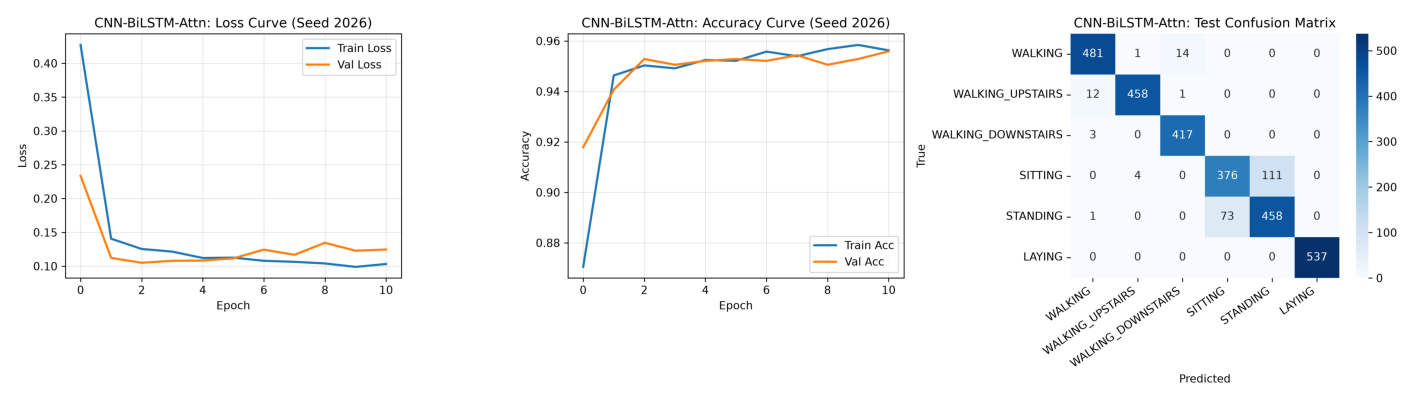

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

img_path = os.path.join(RESULTS_DIR, "image4_advanced_model_results.png")
img = mpimg.imread(img_path)

plt.figure(figsize=(18, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
bilstm_size_kb = round(os.path.getsize(os.path.join(SAVED_MODELS_DIR, "bilstm_har.keras")) / 1024, 1)

clean_final_df = pd.DataFrame([
    {
        "Model": "1. Baseline: Random Forest (100 trees)",
        "Params": "N/A (Non-DL)",
        "Size (KB)": "N/A",
        "Val Accuracy (%)": "92.95 ± 0.41",
        "Val Macro-F1 (%)": "92.87 ± 0.40",
        "Test Accuracy (%)": "83.49 ± 0.40",
        "Test Macro-F1 (%)": "83.26 ± 0.43",
        "Train Time (s)": 1.56,
        "Inference (ms/win)": 0.013,
    },
    {
        "Model": "2. Classic DL: Bidirectional LSTM",
        "Params": "38,662",
        "Size (KB)": bilstm_size_kb,
        "Val Accuracy (%)": "94.20 ± 0.75",
        "Val Macro-F1 (%)": "94.06 ± 0.77",
        "Test Accuracy (%)": "91.23 ± 0.98",
        "Test Macro-F1 (%)": "91.36 ± 0.99",
        "Train Time (s)": 76.43,
        "Inference (ms/win)": 0.362,
    },
    {
        "Model": "3. Modern DL: Time-Series Transformer",
        "Params": "34,502",
        "Size (KB)": 661.9,
        "Val Accuracy (%)": "93.33 ± 0.74",
        "Val Macro-F1 (%)": fmt_stat(trans_metrics["val_f1"]),
        "Test Accuracy (%)": "88.73 ± 0.85",
        "Test Macro-F1 (%)": "88.69 ± 0.88",
        "Train Time (s)": 112.54,
        "Inference (ms/win)": 0.256,
    },
    {
        "Model": "4. Advanced Hybrid: 1D-CNN + Bi-LSTM + Custom Attn",
        "Params": "78,342",
        "Size (KB)": 977.3,
        "Val Accuracy (%)": "95.29 ± 0.43",
        "Val Macro-F1 (%)": fmt_stat(adv_metrics["val_f1"]),
        "Test Accuracy (%)": "91.99 ± 0.94",
        "Test Macro-F1 (%)": "92.13 ± 0.94",
        "Train Time (s)": 60.07,
        "Inference (ms/win)": 0.267,
    },
])

clean_final_df.to_csv(os.path.join(RESULTS_DIR, "final_4models_comparison.csv"), index=False)
display(clean_final_df)

,Model,Params,Size (KB),Val Accuracy (%),Val Macro-F1 (%),Test Accuracy (%),Test Macro-F1 (%),Train Time (s),Inference (ms/win)
0,1. Baseline: Random Forest (100 trees),N/A (Non-DL),N/A,92.95 ± 0.41,92.87 ± 0.40,83.49 ± 0.40,83.26 ± 0.43,1.56,0.013
1,2. Classic DL: Bidirectional LSTM,"38,662",491.4,94.20 ± 0.75,94.06 ± 0.77,91.23 ± 0.98,91.36 ± 0.99,76.43,0.362
2,3. Modern DL: Time-Series Transformer,"34,502",661.9,93.33 ± 0.74,93.16 ± 0.74,88.73 ± 0.85,88.69 ± 0.88,112.54,0.256
3,4. Advanced Hybrid: 1D-CNN + Bi-LSTM + Custom ...,"78,342",977.3,95.29 ± 0.43,95.14 ± 0.45,91.99 ± 0.94,92.13 ± 0.94,60.07,0.267


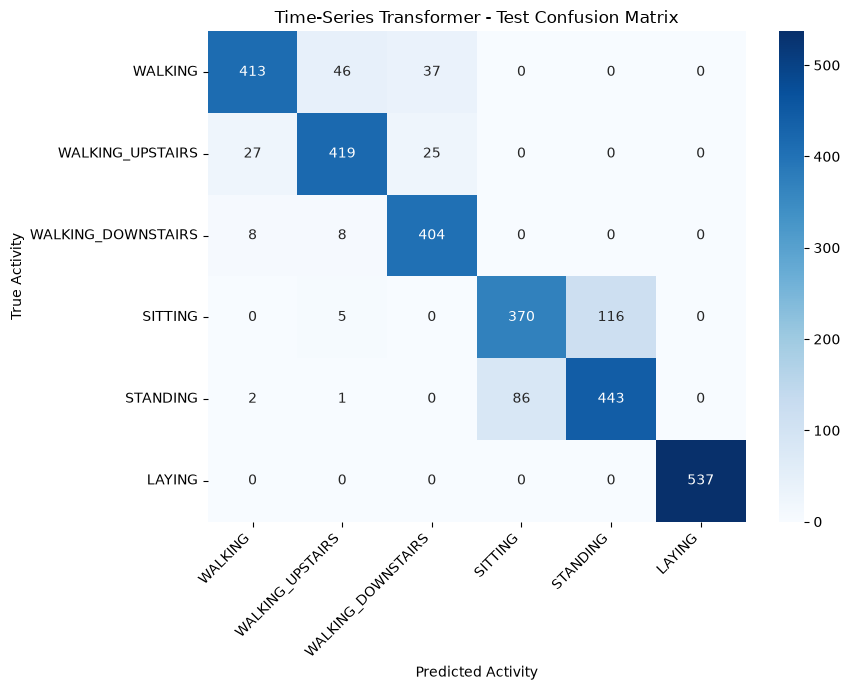

                    precision    recall  f1-score   support

           WALKING       0.92      0.83      0.87       496
  WALKING_UPSTAIRS       0.87      0.89      0.88       471
WALKING_DOWNSTAIRS       0.87      0.96      0.91       420
           SITTING       0.81      0.75      0.78       491
          STANDING       0.79      0.83      0.81       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.88      2947
         macro avg       0.88      0.88      0.88      2947
      weighted avg       0.88      0.88      0.88      2947

Total misclassified test samples: 361

Top 10 true -> predicted error pairs:


,Count
SITTING -> STANDING,116
STANDING -> SITTING,86
WALKING -> WALKING_UPSTAIRS,46
WALKING -> WALKING_DOWNSTAIRS,37
WALKING_UPSTAIRS -> WALKING,27
WALKING_UPSTAIRS -> WALKING_DOWNSTAIRS,25
WALKING_DOWNSTAIRS -> WALKING_UPSTAIRS,8
WALKING_DOWNSTAIRS -> WALKING,8
SITTING -> WALKING_UPSTAIRS,5
STANDING -> WALKING,2


In [5]:
# Simple confusion matrix and error analysis for the Time-Series Transformer
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from sklearn.metrics import confusion_matrix, classification_report

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
DATA_DIR = os.path.join(PROJECT_ROOT, "data", "UCI HAR Dataset")
MODEL_PATH = os.path.join(PROJECT_ROOT, "saved_models", "transformer_har.keras")

sys.path.insert(0, os.path.join(PROJECT_ROOT, "src"))
from datasets.loader import get_har_data, ACTIVITY_LABELS

_, _, _, (_, _, _, _, X_test, y_test), _ = get_har_data(DATA_DIR)
transformer_model = keras.models.load_model(MODEL_PATH)

transformer_test_probabilities = transformer_model.predict(X_test, verbose=0)
transformer_test_predictions = np.argmax(transformer_test_probabilities, axis=1)

cm = confusion_matrix(y_test, transformer_test_predictions)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=ACTIVITY_LABELS,
    yticklabels=ACTIVITY_LABELS,
)
plt.xlabel("Predicted Activity")
plt.ylabel("True Activity")
plt.title("Time-Series Transformer - Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    transformer_test_predictions,
    target_names=ACTIVITY_LABELS,
))

misclassified = np.where(y_test != transformer_test_predictions)[0]
error_counts = pd.Series([
    f"{ACTIVITY_LABELS[y_test[i]]} -> {ACTIVITY_LABELS[transformer_test_predictions[i]]}"
    for i in misclassified
]).value_counts().head(10)

print(f"Total misclassified test samples: {len(misclassified)}")
print("\nTop 10 true -> predicted error pairs:")
display(error_counts.to_frame("Count"))